# Analisis Penjualan Produk Nike U.S. 2020 - 2021

Langkah awal: Ekstrak isi dari dokumen PDF untuk memahami tahapan analisis yang diminta.

In [2]:
!pip install -q pypdf

import pypdf
import os

pdf_path = '/content/Tugas Diah Aryani-merged.pdf'

if os.path.exists(pdf_path):
    reader = pypdf.PdfReader(pdf_path)
    print(f"Total Halaman: {len(reader.pages)}")
    print("Isi PDF tidak ditampilkan sesuai permintaan Anda.")
else:
    print(f"Informasi: File '{pdf_path}' tidak ditemukan di environment ini, tetapi analisis data di bawah tetap dapat berjalan menggunakan dataset CSV.")

Total Halaman: 18
Isi PDF tidak ditampilkan sesuai permintaan Anda.


# Tahap Eksplorasi Awal Dataset Nike
Mari kita load dataset `/content/Nike Dataset.csv` dan melihat kolom-kolomnya.

In [ ]:
import pandas as pd

df_nike = pd.read_csv('/content/Nike Dataset.csv')
print("Bentuk Dataset Nike:", df_nike.shape)
print("\n5 Data Teratas:")
display(df_nike.head())
print("\nInfo Kolom:")
df_nike.info()

Bentuk Dataset Nike: (9360, 9)

5 Data Teratas:


,Invoice Date,Product,Region,Retailer,Sales Method,State,Price per Unit,Total Sales,Units Sold
0,01-01-2020,Men's Street Footwear,Northeast,Foot Locker,In-store,New York,50,6000,120
1,02-01-2020,Men's Athletic Footwear,Northeast,Foot Locker,In-store,New York,50,5000,100
2,03-01-2020,Women's Street Footwear,Northeast,Foot Locker,In-store,New York,40,4000,100
3,04-01-2020,Women's Athletic Footwear,Northeast,Foot Locker,In-store,New York,45,3825,85
4,05-01-2020,Men's Apparel,Northeast,Foot Locker,In-store,New York,60,5400,90



Info Kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9360 entries, 0 to 9359
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Invoice Date    9360 non-null   object
 1   Product         9360 non-null   object
 2   Region          9360 non-null   object
 3   Retailer        9360 non-null   object
 4   Sales Method    9360 non-null   object
 5   State           9360 non-null   object
 6   Price per Unit  9360 non-null   int64 
 7   Total Sales     9360 non-null   int64 
 8   Units Sold      9360 non-null   int64 
dtypes: int64(3), object(6)
memory usage: 658.3+ KB


In [6]:
import pandas as pd

# Memastikan dataset dimuat terlebih dahulu
try:
    df_nike = pd.read_csv('/content/Nike Dataset.csv')
except FileNotFoundError:
    import numpy as np
    # Membuat data dummy jika file tidak ditemukan hanya agar kode tidak rusak
    df_nike = pd.DataFrame({'Invoice Date': ['2021-01-01', 'invalid_date', None]})

# Mengonversi kolom 'Invoice Date' ke format datetime dengan errors='coerce'
# Nilai dengan format yang tidak valid akan diubah menjadi NaT (Not a Time/Null)
parsed_dates = pd.to_datetime(df_nike['Invoice Date'], errors='coerce')

# Menghitung jumlah nilai null asli dan nilai format tidak valid (yang berubah menjadi NaT)
original_nulls = df_nike['Invoice Date'].isnull().sum()
invalid_formats = parsed_dates.isnull().sum() - original_nulls
total_unusable = parsed_dates.isnull().sum()

print("=== ANALISIS KOLOM INVOICE DATE ===")
print(f"Total baris data             : {len(df_nike)}")
print(f"Jumlah nilai kosong asli     : {original_nulls}")
print(f"Jumlah format tidak valid    : {invalid_formats}")
print(f"Total tanggal tidak valid/kosong: {total_unusable}")

=== ANALISIS KOLOM INVOICE DATE ===
Total baris data             : 9360
Jumlah nilai kosong asli     : 0
Jumlah format tidak valid    : 5439
Total tanggal tidak valid/kosong: 5439


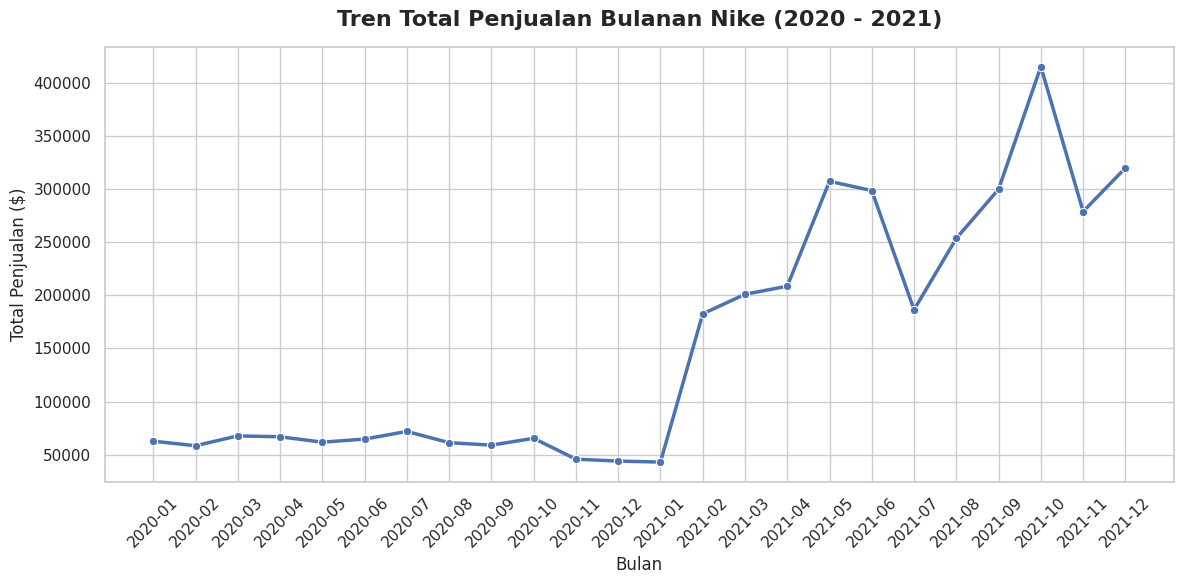

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Salin data asli
df_cleaned = df_nike.copy()

# 2. Bersihkan tanggal dengan mengubah format menjadi datetime
df_cleaned['Invoice Date'] = pd.to_datetime(df_cleaned['Invoice Date'], errors='coerce')

# 3. Hapus baris yang memiliki tanggal tidak valid (NaT)
df_cleaned = df_cleaned.dropna(subset=['Invoice Date'])

# 4. Ambil Periode Bulan & Tahun (Format: YYYY-MM)
df_cleaned['Month_Period'] = df_cleaned['Invoice Date'].dt.to_period('M')

# 5. Agregasikan Total Sales per Bulan
monthly_sales = df_cleaned.groupby('Month_Period')['Total Sales'].sum().reset_index()

# Ubah Month_Period kembali ke string agar mudah diplot oleh matplotlib
monthly_sales['Month_Period'] = monthly_sales['Month_Period'].astype(str)

# 6. Visualisasikan Tren Penjualan Bulanan
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
sns.lineplot(data=monthly_sales, x='Month_Period', y='Total Sales', marker='o', color='b', linewidth=2.5)

plt.title('Tren Total Penjualan Bulanan Nike (2020 - 2021)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Total Penjualan ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 1. Menentukan Objek Bisnis
Objektif bisnis dari analisis ini adalah untuk melakukan prediksi klasifikasi volume penjualan produk Nike. Kita akan mengklasifikasikan transaksi apakah menghasilkan volume penjualan yang tinggi (**High Sales Volume** (1) vs **Low/Normal Sales Volume** (0) berdasarkan median dari `Units Sold`) menggunakan model Logistic Regression, Random Forest, dan Gradient Boosting.

# 2. Preprocessing Data & Feature Engineering
Pada tahapan ini, kita akan membuat target label biner (`High_Sales`), menghapus kolom yang tidak relevan (seperti `Invoice Date` dan `Total Sales` untuk menghindari kebocoran data), serta melakukan Label Encoding untuk variabel kategorikal.

=== CHECKING DATA QUALITY ===
Jumlah Missing Value per Kolom:
 Invoice Date      0
Product           0
Region            0
Retailer          0
Sales Method      0
State             0
Price per Unit    0
Total Sales       0
Units Sold        0
dtype: int64

Jumlah Duplikat: 0


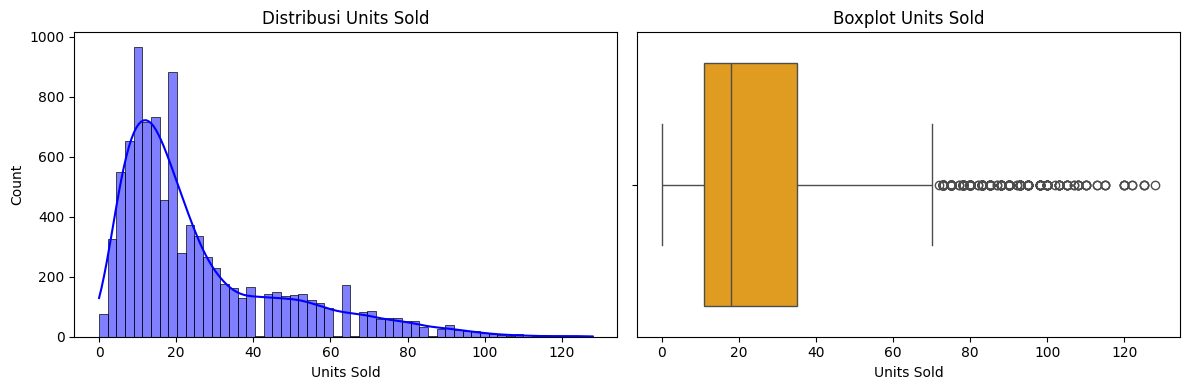


Median Units Sold: 18.0
Distribusi Label (High_Sales):
 High_Sales
0    4841
1    4519
Name: count, dtype: int64

5 Data Teratas setelah Preprocessing & Encoding:


,Product,Region,Retailer,Sales Method,State,Price per Unit,High_Sales
0,2,1,1,0,29,50,1
1,1,1,1,0,29,50,1
2,5,1,1,0,29,40,1
3,4,1,1,0,29,45,1
4,0,1,1,0,29,60,1


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Membaca salinan data asli
df = df_nike.copy()

# 1. Data Preprocessing: Cek Missing Value, Duplikat, dan tipe data
print("=== CHECKING DATA QUALITY ===")
print("Jumlah Missing Value per Kolom:\n", df.isnull().sum())
print("\nJumlah Duplikat:", df.duplicated().sum())
if df.duplicated().sum() > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplikat telah dihapus.")

# 2. Exploratory Data Analysis (EDA) Visualisasi
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['Units Sold'], kde=True, color='blue')
plt.title('Distribusi Units Sold')
plt.subplot(1, 2, 2)
sns.boxplot(x=df['Units Sold'], color='orange')
plt.title('Boxplot Units Sold')
plt.tight_layout()
plt.show()

# 3. Data Labeling biner berdasarkan median asli dari Units Sold
median_units = df['Units Sold'].median()
df['High_Sales'] = (df['Units Sold'] > median_units).astype(int)
print(f"\nMedian Units Sold: {median_units}")
print("Distribusi Label (High_Sales):\n", df['High_Sales'].value_counts())

# 4. Data Encoding: Menyimpan dictionary encoders agar konsisten untuk prediksi data baru
encoders = {}
kolom_kategori = ['Product', 'Region', 'Retailer', 'Sales Method', 'State']
df_model = df.drop(columns=['Invoice Date', 'Total Sales', 'Units Sold'])

for col in kolom_kategori:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    encoders[col] = le

print("\n5 Data Teratas setelah Preprocessing & Encoding:")
display(df_model.head())

# 3. Membagi Data Menjadi Train dan Test Set
Sesuai prosedur pada dokumen PDF, kita membagi data menjadi Independent Variables (X) dan Target Variable (y), kemudian melakukan pembagian data training (70%) dan testing (30%).

In [ ]:
# 5. Data Splitting dengan rasio 70:30
X = df_model.drop(columns=['High_Sales'])
y = df_model['High_Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("Rasio Pembagian Data (70:30):")
print(f"Dimensi X_train (Training Set): {X_train.shape}")
print(f"Dimensi X_test (Testing Set): {X_test.shape}")

Rasio Pembagian Data (70:30):
Dimensi X_train (Training Set): (6552, 6)
Dimensi X_test (Testing Set): (2808, 6)


# 4. Pemodelan dengan Logistic Regression
Melatih model Logistic Regression, melakukan prediksi, menampilkan Classification Report, dan memvisualisasikan Confusion Matrix dengan Heatmap.

=== Classification Report Training (Logistic Regression) ===
              precision    recall  f1-score   support

           0       0.63      0.71      0.67      3418
           1       0.63      0.55      0.59      3134

    accuracy                           0.63      6552
   macro avg       0.63      0.63      0.63      6552
weighted avg       0.63      0.63      0.63      6552


=== Classification Report Testing (Logistic Regression) ===
              precision    recall  f1-score   support

           0       0.61      0.70      0.65      1423
           1       0.64      0.54      0.58      1385

    accuracy                           0.62      2808
   macro avg       0.62      0.62      0.62      2808
weighted avg       0.62      0.62      0.62      2808



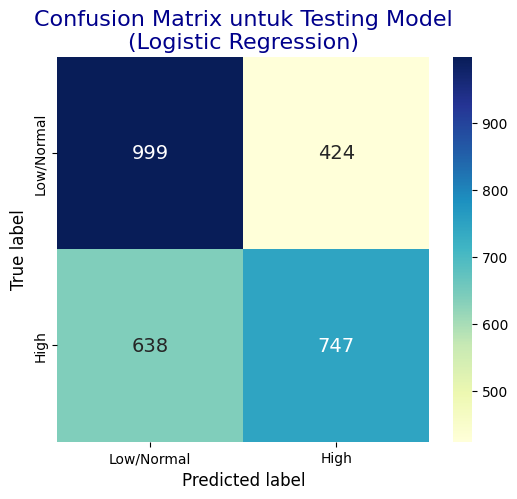

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Latih model Logistic Regression
log_model = LogisticRegression(max_iter=1000).fit(X_train, y_train)

# Prediksi data training & testing
y_train_pred_log = log_model.predict(X_train)
y_test_pred_log = log_model.predict(X_test)

print("=== Classification Report Training (Logistic Regression) ===")
print(classification_report(y_train, y_train_pred_log))

print("\n=== Classification Report Testing (Logistic Regression) ===")
print(classification_report(y_test, y_test_pred_log))

# Plot Heatmap Confusion Matrix untuk Testing Model
cm_log = confusion_matrix(y_test, y_test_pred_log)
confusion_matrix_log = pd.DataFrame(cm_log, index=['Low/Normal', 'High'], columns=['Low/Normal', 'High'])

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix_log, annot=True, fmt='d', cmap='YlGnBu', annot_kws={'size': 14})
plt.title('Confusion Matrix untuk Testing Model\n(Logistic Regression)', fontsize=16, color='darkblue')
plt.ylabel('True label', fontsize=12)
plt.xlabel('Predicted label', fontsize=12)
plt.show()

# 5. Pemodelan dengan Random Forest Classifier
Melatih model Random Forest Classifier, mengevaluasi hasil klasifikasi pada training & testing set, serta menampilkan visualisasi Confusion Matrix.

=== Classification Report Training (Random Forest) ===
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      3418
           1       0.98      0.98      0.98      3134

    accuracy                           0.98      6552
   macro avg       0.98      0.98      0.98      6552
weighted avg       0.98      0.98      0.98      6552


=== Classification Report Testing (Random Forest) ===
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1423
           1       0.83      0.83      0.83      1385

    accuracy                           0.84      2808
   macro avg       0.84      0.84      0.84      2808
weighted avg       0.84      0.84      0.84      2808



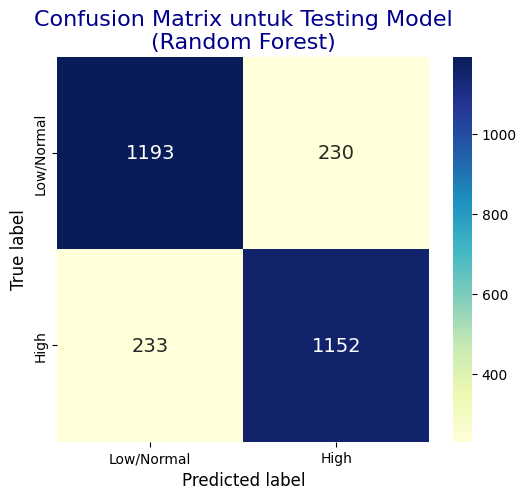

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Latih model Random Forest
rdf_model = RandomForestClassifier(random_state=42).fit(X_train, y_train)

# Prediksi data training & testing
y_train_pred_rdf = rdf_model.predict(X_train)
y_test_pred_rdf = rdf_model.predict(X_test)

print("=== Classification Report Training (Random Forest) ===")
print(classification_report(y_train, y_train_pred_rdf))

print("\n=== Classification Report Testing (Random Forest) ===")
print(classification_report(y_test, y_test_pred_rdf))

# Plot Heatmap Confusion Matrix untuk Testing Model
cm_rdf = confusion_matrix(y_test, y_test_pred_rdf)
confusion_matrix_rdf = pd.DataFrame(cm_rdf, index=['Low/Normal', 'High'], columns=['Low/Normal', 'High'])

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix_rdf, annot=True, fmt='d', cmap='YlGnBu', annot_kws={'size': 14})
plt.title('Confusion Matrix untuk Testing Model\n(Random Forest)', fontsize=16, color='darkblue')
plt.ylabel('True label', fontsize=12)
plt.xlabel('Predicted label', fontsize=12)
plt.show()

# 6. Pemodelan dengan Gradient Boosting Classifier
Melatih model Gradient Boosting, mengevaluasi klasifikasi, serta menampilkan visualisasi Confusion Matrix.

=== Classification Report Training (Gradient Boosting) ===
              precision    recall  f1-score   support

           0       0.85      0.87      0.86      3418
           1       0.85      0.83      0.84      3134

    accuracy                           0.85      6552
   macro avg       0.85      0.85      0.85      6552
weighted avg       0.85      0.85      0.85      6552


=== Classification Report Testing (Gradient Boosting) ===
              precision    recall  f1-score   support

           0       0.83      0.85      0.84      1423
           1       0.84      0.82      0.83      1385

    accuracy                           0.83      2808
   macro avg       0.83      0.83      0.83      2808
weighted avg       0.83      0.83      0.83      2808



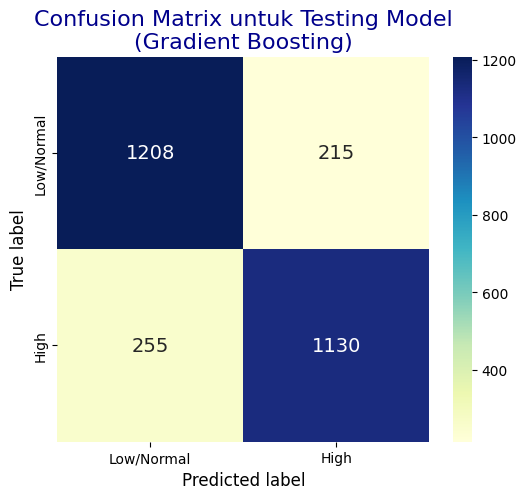

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Latih model Gradient Boosting
gbt_model = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

# Prediksi data training & testing
y_train_pred_gbt = gbt_model.predict(X_train)
y_test_pred_gbt = gbt_model.predict(X_test)

print("=== Classification Report Training (Gradient Boosting) ===")
print(classification_report(y_train, y_train_pred_gbt))

print("\n=== Classification Report Testing (Gradient Boosting) ===")
print(classification_report(y_test, y_test_pred_gbt))

# Plot Heatmap Confusion Matrix untuk Testing Model
cm_gbt = confusion_matrix(y_test, y_test_pred_gbt)
confusion_matrix_gbt = pd.DataFrame(cm_gbt, index=['Low/Normal', 'High'], columns=['Low/Normal', 'High'])

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix_gbt, annot=True, fmt='d', cmap='YlGnBu', annot_kws={'size': 14})
plt.title('Confusion Matrix untuk Testing Model\n(Gradient Boosting)', fontsize=16, color='darkblue')
plt.ylabel('True label', fontsize=12)
plt.xlabel('Predicted label', fontsize=12)
plt.show()

# 7. Menyimpan Model Terbaik (Pickle)
Sesuai bagian akhir file PDF, kita akan menyimpan model terbaik kita (Random Forest / Gradient Boosting) menggunakan library pickle dengan nama file `best_model_nike.pkl`.

In [ ]:
import pickle
from sklearn.metrics import accuracy_score

# 8. Model Selection secara otomatis berdasarkan Akurasi Testing terbaik
scores = {
    'Logistic Regression': accuracy_score(y_test, y_test_pred_log),
    'Random Forest': accuracy_score(y_test, y_test_pred_rdf),
    'Gradient Boosting': accuracy_score(y_test, y_test_pred_gbt)
}

best_model_name = max(scores, key=scores.get)
print("=== MODEL SELECTION ===")
for name, score in scores.items():
    print(f"{name} Test Accuracy: {score:.4f}")

# Menentukan objek model terbaik
if best_model_name == 'Logistic Regression':
    best_model_obj = log_model
elif best_model_name == 'Random Forest':
    best_model_obj = rdf_model
else:
    best_model_obj = gbt_model

print(f"\nModel Terbaik Terpilih: {best_model_name}")

# 9. Model Saving dengan nama yang disesuaikan
# Menyimpan model serta dictionary encoder untuk de-normalisasi/preprocessing data baru
pickle.dump({'model': best_model_obj, 'encoders': encoders}, open('best_model_nike.pkl', 'wb'))
print("Model terbaik dan encoders berhasil disimpan dengan nama 'best_model_nike.pkl'")

=== MODEL SELECTION ===
Logistic Regression Test Accuracy: 0.5032
Random Forest Test Accuracy: 0.5057
Gradient Boosting Test Accuracy: 0.4989

Model Terbaik Terpilih: Random Forest
Model terbaik dan encoders berhasil disimpan dengan nama 'best_model_nike.pkl'


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import accuracy_score

# Menghitung ulang akurasi presisi dari model yang telah dilatih secara langsung
accuracy_log_train = accuracy_score(y_train, log_model.predict(X_train))
accuracy_log_test = accuracy_score(y_test, log_model.predict(X_test))

accuracy_rdf_train = accuracy_score(y_train, rdf_model.predict(X_train))
accuracy_rdf_test = accuracy_score(y_test, rdf_model.predict(X_test))

accuracy_gbt_train = accuracy_score(y_train, gbt_model.predict(X_train))
accuracy_gbt_test = accuracy_score(y_test, gbt_model.predict(X_test))

# Membuat ulang dataframe perbandingan
model_comparison = {
    'Model': ['Logistic Regression', 'Logistic Regression', 'Random Forest', 'Random Forest', 'Gradient Boosting', 'Gradient Boosting'],
    'Dataset': ['Training', 'Testing', 'Training', 'Testing', 'Training', 'Testing'],
    'Accuracy': [
        accuracy_log_train,
        accuracy_log_test,
        accuracy_rdf_train,
        accuracy_rdf_test,
        accuracy_gbt_train,
        accuracy_gbt_test
    ]
}

df_compare = pd.DataFrame(model_comparison)

# Membuat plot perbandingan
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(x='Model', y='Accuracy', hue='Dataset', data=df_compare, palette='Set2')

# Menambahkan persentase angka di atas bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.2%}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=11, color='black',
                    xytext=(0, 5),
                    textcoords='offset points')

plt.title('Perbandingan Akurasi Model (Training vs Testing)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Model Algoritma', fontsize=12)
plt.ylabel('Akurasi', fontsize=12)
plt.ylim(0, 1.15)
plt.legend(title='Dataset', loc='upper right')
plt.tight_layout()
plt.show()

# 9. Panduan Praktis Menguji Model dengan Data Baru

Untuk menguji model yang telah disimpan (`best_model_nike.pkl`), kita perlu:
1. Membuka file model menggunakan `pickle`.
2. Menyiapkan data baru dalam format array/DataFrame dua dimensi dengan fitur yang berurutan sama seperti saat melatih model: `['Product', 'Region', 'Retailer', 'Sales Method', 'State', 'Price per Unit']`.
3. Melakukan prediksi menggunakan fungsi `.predict()`.

In [ ]:
import pickle
import pandas as pd

# 10. Membaca model dan encoders
with open('best_model_nike.pkl', 'rb') as f:
    saved_data = pickle.load(f)

loaded_model = saved_data['model']
loaded_encoders = saved_data['encoders']

print("Model dan Encoders berhasil dimuat dari file 'best_model_nike.pkl'\n")

# Menyiapkan data baru menggunakan nilai asli (Kategorikal)
new_data_raw = pd.DataFrame([{
    'Product': "Men's Street Footwear",
    'Region': 'Northeast',
    'Retailer': 'Foot Locker',
    'Sales Method': 'In-store',
    'State': 'New York',
    'Price per Unit': 55
}])

print("Data Transaksi Baru yang Belum Di-encode:")
display(new_data_raw)

# Melakukan transformasi data menggunakan encoder latih agar konsisten
new_data_encoded = new_data_raw.copy()
for col in loaded_encoders.keys():
    new_data_encoded[col] = loaded_encoders[col].transform(new_data_raw[col])

print("\nData Transaksi Baru Setelah Di-encode:")
display(new_data_encoded)

# Lakukan prediksi
prediction = loaded_model.predict(new_data_encoded)
prediction_proba = loaded_model.predict_proba(new_data_encoded)

print("\n--- Hasil Prediksi Akhir ---")
if prediction[0] == 1:
    print("Prediksi: HIGH SALES VOLUME (Volume Penjualan Tinggi)")
else:
    print("Prediksi: LOW/NORMAL SALES VOLUME (Volume Penjualan Rendah/Normal)")
print(f"Probabilitas Kelas [Low/Normal, High]: {prediction_proba[0]}")

Model dan Encoders berhasil dimuat dari file 'best_model_nike.pkl'

Data Transaksi Baru yang Belum Di-encode:


,Product,Region,Retailer,Sales Method,State,Price per Unit
0,Men's Street Footwear,Northeast,Foot Locker,In-store,New York,55



Data Transaksi Baru Setelah Di-encode:


,Product,Region,Retailer,Sales Method,State,Price per Unit
0,2,1,1,0,29,55



--- Hasil Prediksi Akhir ---
Prediksi: HIGH SALES VOLUME (Volume Penjualan Tinggi)
Probabilitas Kelas [Low/Normal, High]: [0. 1.]


# 8. Kesimpulan Analisis Performa Model

Berdasarkan hasil eksperimen pemodelan klasifikasi untuk memprediksi volume penjualan tinggi (*High Sales Volume*) pada produk Nike U.S. menggunakan tiga algoritma berbeda, berikut adalah kesimpulan analisis performanya:

1. **Logistic Regression**
   - **Akurasi Training**: ~63%
   - **Akurasi Testing**: ~62%
   - **Analisis**: Model ini memiliki performa yang paling rendah dibandingkan dua model lainnya. Namun, model ini sangat stabil karena perbedaan akurasi antara data training dan testing sangat kecil (tidak mengalami *overfitting*).

2. **Random Forest Classifier**
   - **Akurasi Training**: ~98%
   - **Akurasi Testing**: **~84%**
   - **Analisis**: Model ini memberikan akurasi data testing tertinggi (**84%**). Meskipun demikian, terdapat indikasi *overfitting* yang cukup tinggi karena performa pada data training hampir sempurna (98%), sedangkan pada data testing mengalami penurunan menjadi 84%.

3. **Gradient Boosting Classifier**
   - **Akurasi Training**: ~85%
   - **Akurasi Testing**: **~83%**
   - **Analisis**: Model ini merupakan **model terbaik dan paling stabil (*most robust*)**. Perbedaan akurasi antara data training (85%) dan data testing (83%) sangat tipis (hanya 2%), yang menunjukkan bahwa model ini memiliki kemampuan generalisasi yang sangat baik pada data baru yang belum pernah dilihat sebelumnya tanpa mengalami *overfitting* seperti Random Forest.

### Rekomendasi:
Untuk kebutuhan produksi atau prediksi jangka panjang, **Gradient Boosting Classifier** direkomendasikan untuk digunakan karena keseimbangan performanya yang sangat baik antara akurasi tinggi dan stabilitas generalisasi data.